<a href="https://colab.research.google.com/github/Mahala20-20/house-price-prediction/blob/main/house_price_pridiction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries loaded successfully!
Mounted at /content/drive
Enter your Kaggle API token: ··········
Dataset URL: https://www.kaggle.com/datasets/zafarali27/house-price-prediction-dataset
License(s): CC0-1.0
house-price-prediction-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  /content/drive/MyDrive/House Price Prediction/house-price-prediction-dataset.zip
  inflating: /content/drive/MyDrive/House Price Prediction/House Price Prediction Dataset.csv  
Dataset loaded successfully!
Features shape after encoding: (2000, 12)
Predicted House Price for sample: $532155.31
Model trained and test predictions generated successfully!


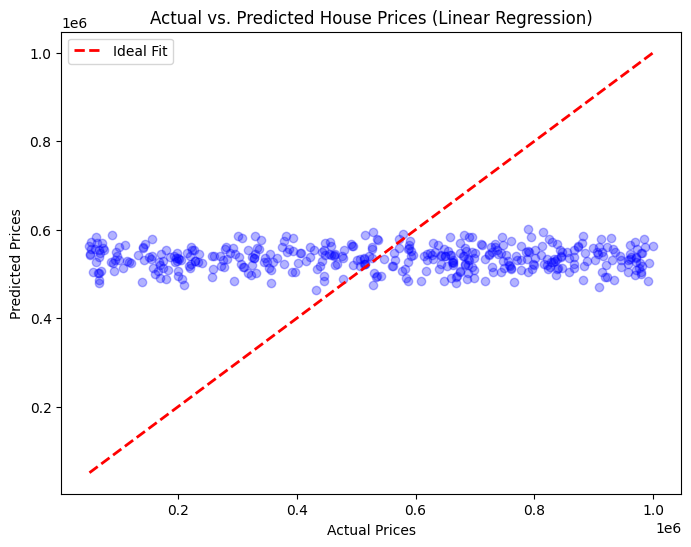

Random Forest MAE: 252518.030125
Random Forest R² Score: -0.09640442128237403

California Housing Dataset Head:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
California Linear Regression MAE: 0.5332001304956561
California Linear Regression R² Score: 0.5757877060324512


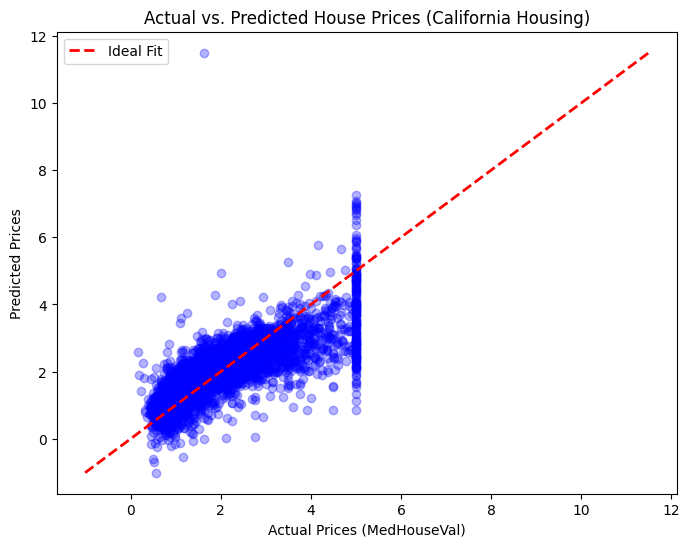

In [ ]:

# SETUP AND DATA LOADING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from getpass import getpass

print("Libraries loaded successfully!")

from google.colab import drive
drive.mount('/content/drive')

!pip install -q kaggle
os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

!kaggle datasets download \
    -d zafarali27/house-price-prediction-dataset \
    -p "/content/drive/MyDrive/House Price Prediction"

!unzip -o "/content/drive/MyDrive/House Price Prediction/house-price-prediction-dataset.zip" \
    -d "/content/drive/MyDrive/House Price Prediction"

file_path = "/content/drive/MyDrive/House Price Prediction/House Price Prediction Dataset.csv"
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")


# CUSTOM DATA PREPROCESSING

# Separate features (X) and target (y)
X = df.drop("Price", axis=1)
y = df["Price"]

# Remove 'Id' as it's just an identifier
X = X.drop("Id", axis=1)

# Handle categorical columns using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)
print("Features shape after encoding:", X.shape)

# Train/Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# LINEAR REGRESSION & CUSTOM PREDICTION

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

#CUSTOM HOUSE PREDICTION
sample_house = pd.DataFrame({
    'Area': [2000],
    'Bedrooms': [3],
    'Bathrooms': [2],
    'Floors': [2],
    'YearBuilt': [2015],
    'Location': ['Downtown'],
    'Condition': ['Good'],
    'Garage': ['Yes']
})

sample_encoded = pd.get_dummies(sample_house)
sample_encoded = sample_encoded.reindex(columns=X.columns, fill_value=0)
predicted_price = model.predict(sample_encoded)
print(f"Predicted House Price for sample: ${predicted_price[0]:.2f}")

# Predict on test set and plot
y_pred = model.predict(X_test)
print("Model trained and test predictions generated successfully!")

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue')
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs. Predicted House Prices (Linear Regression)")

pmin = min(y_test.min(), y_pred.min())
pmax = max(y_test.max(), y_pred.max())
plt.plot([pmin, pmax], [pmin, pmax], color='red', linestyle='--', lw=2, label="Ideal Fit")
plt.legend()
plt.show()


# RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest R² Score:", r2_score(y_test, rf_pred))

#CALIFORNIA HOUSING DATASET

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df_cali = housing.frame
print("\nCalifornia Housing Dataset Head:")
print(df_cali.head())

X_cali = df_cali.drop("MedHouseVal", axis=1)
y_cali = df_cali["MedHouseVal"]

X_train_cali, X_test_cali, y_train_cali, y_test_cali = train_test_split(
    X_cali, y_cali, test_size=0.2, random_state=42
)

model_cali = LinearRegression()
model_cali.fit(X_train_cali, y_train_cali)
y_pred_cali = model_cali.predict(X_test_cali)

print("California Linear Regression MAE:", mean_absolute_error(y_test_cali, y_pred_cali))
print("California Linear Regression R² Score:", r2_score(y_test_cali, y_pred_cali))

plt.figure(figsize=(8, 6))
plt.scatter(y_test_cali, y_pred_cali, alpha=0.3, color='blue')
plt.xlabel("Actual Prices (MedHouseVal)")
plt.ylabel("Predicted Prices")
plt.title("Actual vs. Predicted House Prices (California Housing)")

pmin_cali = min(y_test_cali.min(), y_pred_cali.min())
pmax_cali = max(y_test_cali.max(), y_pred_cali.max())
plt.plot([pmin_cali, pmax_cali], [pmin_cali, pmax_cali], color='red', linestyle='--', lw=2, label="Ideal Fit")

plt.legend()
plt.show()

In [ ]:
import pandas as pd

# 1. Input the specific details of the house you want to evaluate
sample_house = pd.DataFrame({
    'Area': [2500],
    'Bedrooms': [4],
    'Bathrooms': [3],
    'Floors': [2],
    'YearBuilt': [2018],
    'Location': ['Suburban'],
    'Condition': ['Excellent'],
    'Garage': ['Yes']
})

# 2. Encode the categorical variables to match the model's format
sample_encoded = pd.get_dummies(sample_house)

# 3. Align the columns exactly with the training dataset's structure
sample_encoded = sample_encoded.reindex(columns=X.columns, fill_value=0)

# 4. Generate and format the predicted price
predicted_price = model.predict(sample_encoded)
print(f"Predicted House Price: ${predicted_price[0]:,.2f}")

Predicted House Price: $547,087.85
